## US-04: Análisis exploratorio de datos (EDA)

**Como** científico de datos,  
**quiero** analizar los patrones de comportamiento de los clientes,  
**para** identificar las variables relacionadas con el abandono (*Customer Churn*).

### Criterios de aceptación

- [ ] Mostrar la distribución de clientes.
- [ ] Mostrar la tasa de abandono de clientes (*Churn Rate*).
- [ ] Generar gráficos y métricas descriptivas que permitan comprender el comportamiento de los datos.

#Carga de datos

In [4]:
import pandas as pd

df = pd.read_csv(
    "Telco_customer_churn.csv",
    sep=";"
)

print(df.shape)
df.head()

(7043, 33)


,CustomerID,Count,Country,State,City,Zip Code,Lat Long,Latitude,Longitude,Gender,...,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Label,Churn Value,Churn Score,CLTV,Churn Reason
0,3668-QPYBK,1,United States,California,Los Angeles,90003,"33.964131, -118.272783",33.964131,-118.272783,Male,...,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,1,86,3239,Competitor made better offer
1,9237-HQITU,1,United States,California,Los Angeles,90005,"34.059281, -118.30742",34.059281,-118.307420,Female,...,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,1,67,2701,Moved
2,9305-CDSKC,1,United States,California,Los Angeles,90006,"34.048013, -118.293953",34.048013,-118.293953,Female,...,Month-to-month,Yes,Electronic check,99.65,820.5,Yes,1,86,5372,Moved
3,7892-POOKP,1,United States,California,Los Angeles,90010,"34.062125, -118.315709",34.062125,-118.315709,Female,...,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes,1,84,5003,Moved
4,0280-XJGEX,1,United States,California,Los Angeles,90015,"34.039224, -118.266293",34.039224,-118.266293,Male,...,Month-to-month,Yes,Bank transfer (automatic),103.70,5036.3,Yes,1,89,5340,Competitor had better devices


#Información general

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 33 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   CustomerID         7043 non-null   str    
 1   Count              7043 non-null   int64  
 2   Country            7043 non-null   str    
 3   State              7043 non-null   str    
 4   City               7043 non-null   str    
 5   Zip Code           7043 non-null   int64  
 6   Lat Long           7043 non-null   str    
 7   Latitude           7043 non-null   float64
 8   Longitude          7043 non-null   float64
 9   Gender             7043 non-null   str    
 10  Senior Citizen     7043 non-null   str    
 11  Partner            7043 non-null   str    
 12  Dependents         7043 non-null   str    
 13  Tenure Months      7043 non-null   int64  
 14  Phone Service      7043 non-null   str    
 15  Multiple Lines     7043 non-null   str    
 16  Internet Service   7043 non-null   

## 📊 Información General del Dataset

### Características principales

- **Total de registros:** 7,043
- **Total de variables:** 33
- **Estado de carga:** No se observan problemas durante la carga de los datos.
- **Tipos de variables:** Se identifican variables categóricas y numéricas.
- **Contexto de los datos:** La información corresponde a clientes de empresas de telecomunicaciones.

### Resumen

El dataset contiene información de **7,043 clientes**, distribuidos en **33 variables**, }
que incluyen características categóricas y numéricas. Los datos se cargaron correctamente 
y constituyen la base para realizar el análisis exploratorio de datos (EDA).

In [6]:
df.columns.tolist()

['CustomerID',
 'Count',
 'Country',
 'State',
 'City',
 'Zip Code',
 'Lat Long',
 'Latitude',
 'Longitude',
 'Gender',
 'Senior Citizen',
 'Partner',
 'Dependents',
 'Tenure Months',
 'Phone Service',
 'Multiple Lines',
 'Internet Service',
 'Online Security',
 'Online Backup',
 'Device Protection',
 'Tech Support',
 'Streaming TV',
 'Streaming Movies',
 'Contract',
 'Paperless Billing',
 'Payment Method',
 'Monthly Charges',
 'Total Charges',
 'Churn Label',
 'Churn Value',
 'Churn Score',
 'CLTV',
 'Churn Reason']

#Verificar si existen valores nulos.

In [7]:
df.isnull().sum()

CustomerID              0
Count                   0
Country                 0
State                   0
City                    0
Zip Code                0
Lat Long                0
Latitude                0
Longitude               0
Gender                  0
Senior Citizen          0
Partner                 0
Dependents              0
Tenure Months           0
Phone Service           0
Multiple Lines          0
Internet Service        0
Online Security         0
Online Backup           0
Device Protection       0
Tech Support            0
Streaming TV            0
Streaming Movies        0
Contract                0
Paperless Billing       0
Payment Method          0
Monthly Charges         0
Total Charges           0
Churn Label             0
Churn Value             0
Churn Score             0
CLTV                    0
Churn Reason         5174
dtype: int64

In [8]:
df.describe()

,Count,Zip Code,Latitude,Longitude,Tenure Months,Monthly Charges,Churn Value,Churn Score,CLTV
count,7043.0,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000
mean,1.0,93521.964646,36.282441,-119.798880,32.371149,64.761692,0.265370,58.699418,4400.295755
std,0.0,1865.794555,2.455723,2.157889,24.559481,30.090047,0.441561,21.525131,1183.057152
min,1.0,90001.000000,32.555828,-124.301372,0.000000,18.250000,0.000000,5.000000,2003.000000
25%,1.0,92102.000000,34.030915,-121.815412,9.000000,35.500000,0.000000,40.000000,3469.000000
50%,1.0,93552.000000,36.391777,-119.730885,29.000000,70.350000,0.000000,61.000000,4527.000000
75%,1.0,95351.000000,38.224869,-118.043237,55.000000,89.850000,1.000000,75.000000,5380.500000
max,1.0,96161.000000,41.962127,-114.192901,72.000000,118.750000,1.000000,100.000000,6500.000000


### 📈 Medidas estadísticas descriptivas

Se calcularán las siguientes medidas estadísticas para analizar el comportamiento de las variables numéricas:

1. **Media:** Valor promedio de los datos.
2. **Mínimo:** Valor más pequeño registrado.
3. **Máximo:** Valor más grande registrado.
4. **Desviación estándar:** Medida que permite conocer qué tan dispersos están los datos respecto a la media.

In [9]:
df["Churn Label"].value_counts()

Churn Label
No     5174
Yes    1869
Name: count, dtype: int64

In [10]:
df["Churn Label"].value_counts(normalize=True) * 100

Churn Label
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64

# Tasa de abandono de clientes

Se identificó que de un total de **7043 clientes**:

- **5174** clientes permanecieron activos.
- **1869** clientes abandonaron el servicio.

La tasa de abandono observada es del **26.54%**, mientras que el **73.46%** de los clientes continúan utilizando los servicios de la compañía.

#gráfica Distribución de abandono de clientes

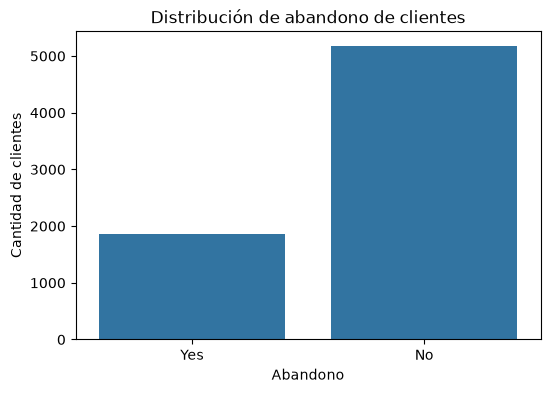

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(6,4))

sns.countplot(
    data=df,
    x="Churn Label"
)

plt.title("Distribución de abandono de clientes")
plt.xlabel("Abandono")
plt.ylabel("Cantidad de clientes")

plt.show()

#Gráfica 1: Contrato vs Abandono

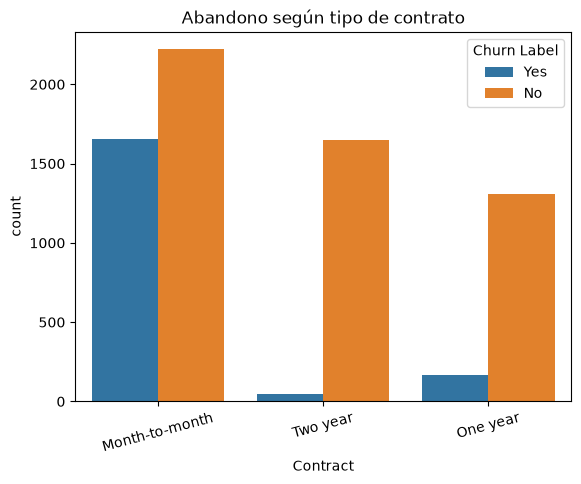

In [15]:
sns.countplot(
    data=df,
    x="Contract",
    hue="Churn Label"
)

plt.title("Abandono según tipo de contrato")
plt.xticks(rotation=15)
plt.show()

#Gráfica 2: Género

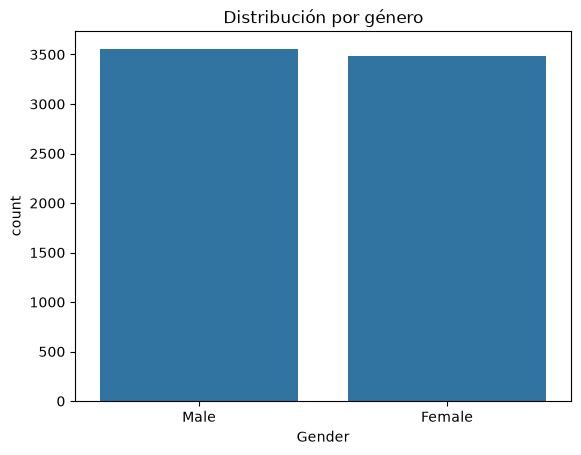

In [16]:
sns.countplot(
    data=df,
    x="Gender"
)

plt.title("Distribución por género")
plt.show()

#Gráfica 3: Antigüedad del cliente

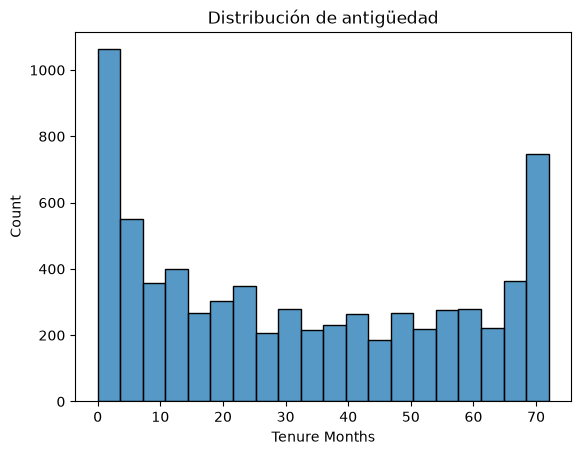

In [17]:
sns.histplot(
    data=df,
    x="Tenure Months",
    bins=20
)

plt.title("Distribución de antigüedad")
plt.show()

# Conclusiones

- El dataset contiene **7043 clientes** y **33 variables**.
- La tasa de abandono observada es del **26.54%**.
- El **73.46%** de los clientes permanecen activos.
- Las variables `Contract`, `Tenure Months` y `Monthly Charges` parecen relevantes para estudiar el abandono.
- El dataset presenta información suficiente para construir modelos predictivos en la **US-05**.